In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

clean_telco_df = pd.read_csv("../data/clean_telco_df.csv")

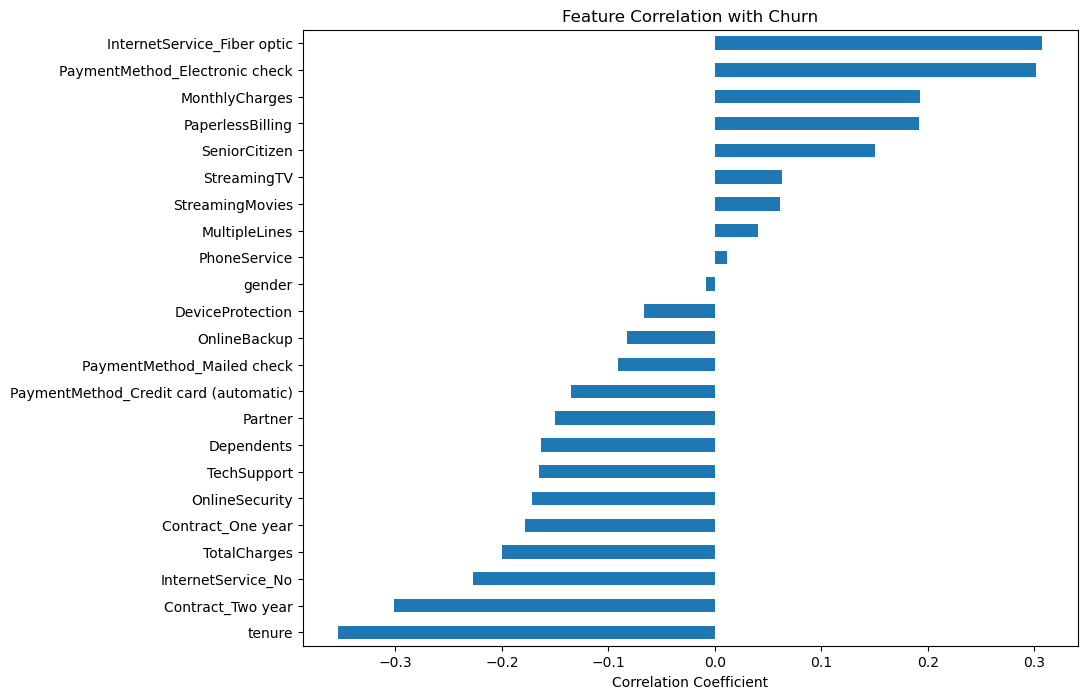

In [2]:
# feature correlation with churn

corr = clean_telco_df.corr()["Churn"].drop("Churn").sort_values()

plt.figure(figsize=(10,8))
corr.plot(kind="barh")
plt.title("Feature Correlation with Churn")
plt.xlabel("Correlation Coefficient")
plt.show()

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# train/test split
X = clean_telco_df.drop("Churn", axis=1)
y = clean_telco_df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# scale features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# training baseline logistic regression model
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

# making predictions
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

In [4]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

# accuracy
print(accuracy_score(y_test, y_pred))

# confusion matrix
print(confusion_matrix(y_test, y_pred))

# classification report
print(classification_report(y_test, y_pred))

# ROC AUC
print(roc_auc_score(y_test, y_prob))

0.8038379530916845
[[916 117]
 [159 215]]
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407

0.8357090350000776


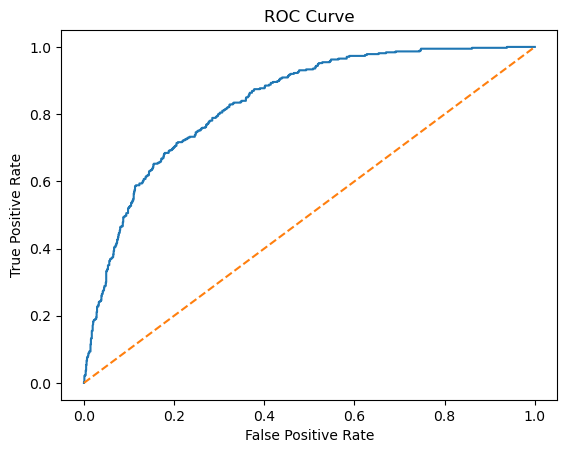

,Feature,Coefficient
16,InternetService_Fiber optic,0.691401
15,TotalCharges,0.618565
11,StreamingTV,0.235872
12,StreamingMovies,0.222537
6,MultipleLines,0.207352
19,PaymentMethod_Electronic check,0.182485
13,PaperlessBilling,0.142861
1,SeniorCitizen,0.070869
9,DeviceProtection,0.062136
20,PaymentMethod_Mailed check,0.034534


In [5]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.plot(fpr, tpr)
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()

# interpreting

import pandas as pd

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
}).sort_values(by="Coefficient", ascending=False)

coefficients


In [6]:
from sklearn.metrics import classification_report, confusion_matrix

# optimized threshold
y_pred_03 = (y_prob > 0.3).astype(int)
print(confusion_matrix(y_test, y_pred_03))
print(classification_report(y_test, y_pred_03))

[[762 271]
 [ 90 284]]
              precision    recall  f1-score   support

           0       0.89      0.74      0.81      1033
           1       0.51      0.76      0.61       374

    accuracy                           0.74      1407
   macro avg       0.70      0.75      0.71      1407
weighted avg       0.79      0.74      0.76      1407



In [7]:
from sklearn.ensemble import RandomForestClassifier
# random forest classifier
rf = RandomForestClassifier()
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:, 1]

In [8]:
from sklearn.metrics import roc_auc_score, classification_report

print(classification_report(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_prob))

              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1033
           1       0.64      0.50      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407

ROC-AUC: 0.8225600633635485


In [9]:
import pandas as pd

rf_importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

rf_importance.head(10)

TotalCharges                      0.192588
MonthlyCharges                    0.174094
tenure                            0.171121
InternetService_Fiber optic       0.046942
PaymentMethod_Electronic check    0.037241
Contract_Two year                 0.036574
gender                            0.028721
PaperlessBilling                  0.026802
OnlineSecurity                    0.024546
Contract_One year                 0.024413
dtype: float64

In [10]:
# tuning

rf_tuned = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

rf_tuned.fit(X_train, y_train)

rf_tuned_pred = rf_tuned.predict(X_test)
rf_tuned_prob = rf_tuned.predict_proba(X_test)[:,1]

print(classification_report(y_test, rf_tuned_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_tuned_prob))

              precision    recall  f1-score   support

           0       0.83      0.90      0.87      1033
           1       0.65      0.51      0.57       374

    accuracy                           0.80      1407
   macro avg       0.74      0.70      0.72      1407
weighted avg       0.78      0.80      0.79      1407

ROC-AUC: 0.8395903111750728


In [11]:
import sys
!{sys.executable} -m pip install xgboost

import xgboost

In [12]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    random_state=42,
    use_label_encoder=False,
    eval_metric="logloss"
)

xgb.fit(X_train, y_train)
xgb_pred = xgb.predict(X_test)
xgb_prob = xgb.predict_proba(X_test)[:, 1]

c:\Users\dillo\anaconda3\envs\ChurnDsProj\Lib\site-packages\xgboost\training.py:200: UserWarning: [15:36:33] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [13]:
from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(y_test, xgb_pred))
print("ROC-AUC:", roc_auc_score(y_test, xgb_prob))

              precision    recall  f1-score   support

           0       0.84      0.86      0.85      1033
           1       0.59      0.55      0.57       374

    accuracy                           0.78      1407
   macro avg       0.71      0.70      0.71      1407
weighted avg       0.77      0.78      0.78      1407

ROC-AUC: 0.8196494297798325


In [14]:
import numpy as np

# threshold tuning
xgb_tuned = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

xgb_tuned.fit(X_train, y_train)
xgb_tuned_pred = xgb_tuned.predict(X_test)
xgb_tuned_prob = xgb_tuned.predict_proba(X_test)[:, 1]

thresholds = np.arange(0.1, 0.9, 0.1)

for t in thresholds:
    y_pred_t_tuned = (xgb_tuned_prob > t).astype(int)
    print(f"\nThreshold: {t}")
    print(classification_report(y_test, y_pred_t_tuned))


Threshold: 0.1
              precision    recall  f1-score   support

           0       0.96      0.50      0.65      1033
           1       0.40      0.94      0.56       374

    accuracy                           0.61      1407
   macro avg       0.68      0.72      0.61      1407
weighted avg       0.81      0.61      0.63      1407


Threshold: 0.2
              precision    recall  f1-score   support

           0       0.92      0.65      0.76      1033
           1       0.47      0.85      0.60       374

    accuracy                           0.70      1407
   macro avg       0.69      0.75      0.68      1407
weighted avg       0.80      0.70      0.72      1407


Threshold: 0.30000000000000004
              precision    recall  f1-score   support

           0       0.90      0.74      0.81      1033
           1       0.51      0.77      0.62       374

    accuracy                           0.74      1407
   macro avg       0.71      0.75      0.71      1407
weighted a

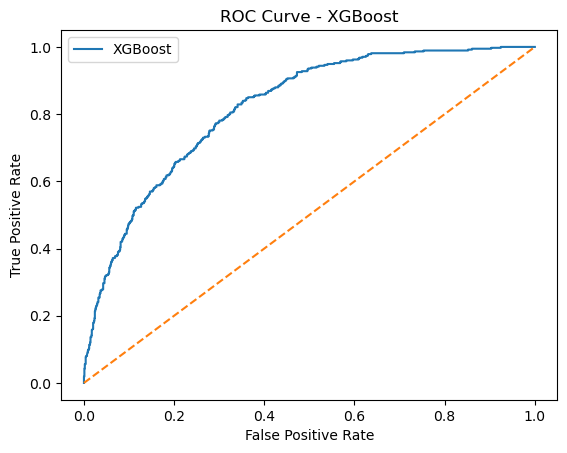

In [15]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

# ROC curve for XGBoost
fpr_xgb, tpr_xgb, thresholds_xgb = roc_curve(y_test, xgb_prob)

plt.figure()
plt.plot(fpr_xgb, tpr_xgb, label="XGBoost")
plt.plot([0,1], [0,1], linestyle="--")  # random model baseline
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - XGBoost")
plt.legend()
plt.show()

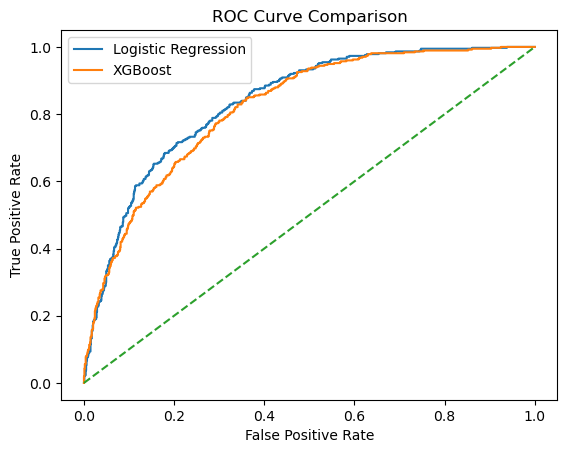

In [16]:
from sklearn.metrics import roc_curve

# Logistic
fpr_log, tpr_log, _ = roc_curve(y_test, y_prob)

# XGBoost
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_prob)

plt.figure()
plt.plot(fpr_log, tpr_log, label="Logistic Regression")
plt.plot(fpr_xgb, tpr_xgb, label="XGBoost")
plt.plot([0,1], [0,1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

InternetService_Fiber optic       0.428601
Contract_Two year                 0.183018
Contract_One year                 0.095891
InternetService_No                0.053473
StreamingMovies                   0.023632
tenure                            0.023485
OnlineSecurity                    0.015021
PaymentMethod_Electronic check    0.014857
MultipleLines                     0.013777
StreamingTV                       0.013468
dtype: float32


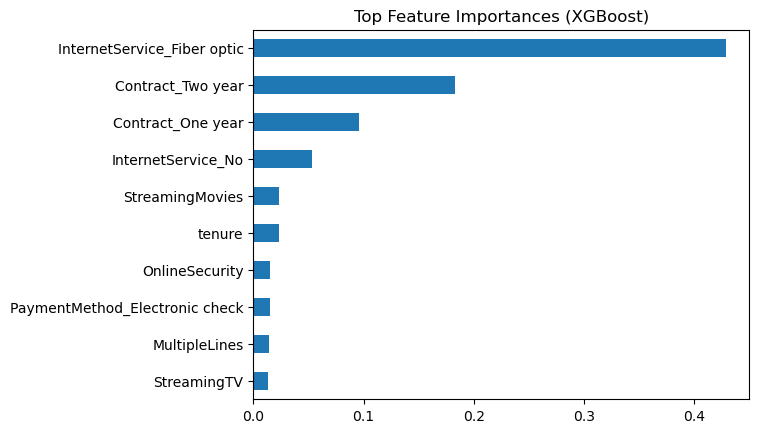

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

xgb_importance = pd.Series(
    xgb.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(xgb_importance.head(10))

xgb_importance.head(10).plot(kind="barh")
plt.title("Top Feature Importances (XGBoost)")
plt.gca().invert_yaxis()
plt.show()

In [18]:
import sys
!{sys.executable} -m pip install shap

import shap

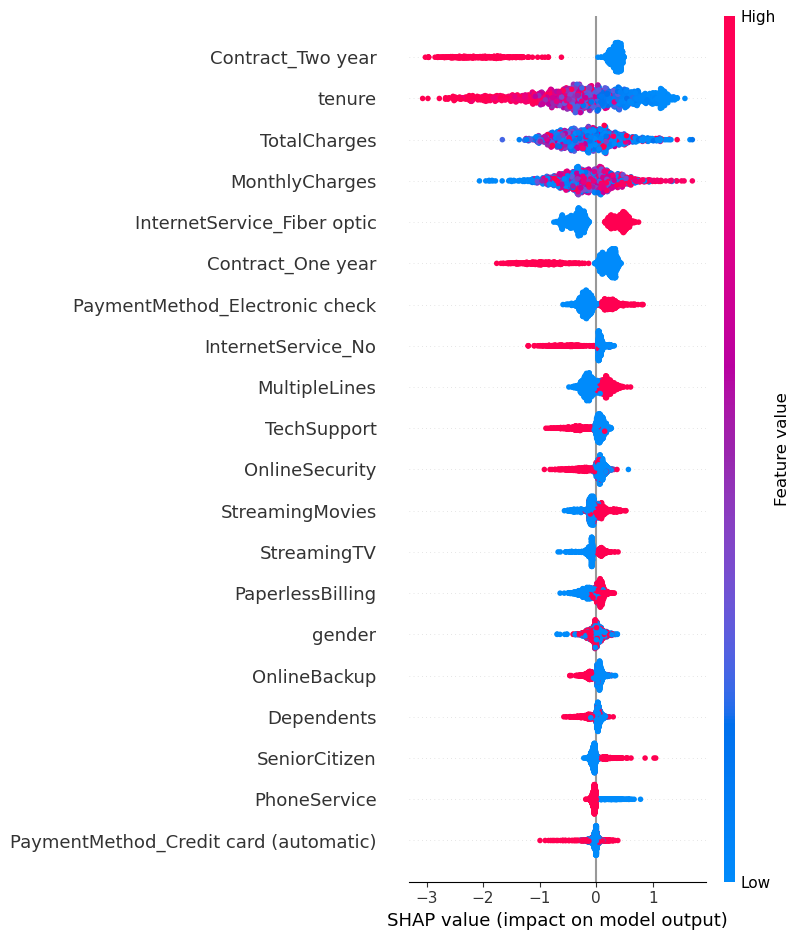

In [19]:
import shap

# shap analysis
explainer = shap.Explainer(xgb)
shap_values = explainer(X_test)

shap.summary_plot(shap_values, X_test)